# BHSD vs PhysioNet CT domain comparison
동일한 Dataset001 NIfTI를 사용해 두 출처의 영상 도메인 차이를 비교합니다. 원본은 수정하지 않고 통계표와 그림만 `runs/analysis/bhsd_physionet_domain_comparison`에 저장합니다.

In [3]:
# 1. 경로와 분석 설정
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk

ROOT = Path('/home/stu03/workspace/model').resolve()
DATA_ROOT = Path('/home/stu03/workspace/datasets/hemorrhage/v1/model_ready/nnunet').resolve()
DATASET_ROOT = DATA_ROOT / 'nnUNet_raw/Dataset001_ICHBinary'
OUTPUT_DIR = ROOT / 'runs/analysis/bhsd_physionet_domain_comparison'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
MAX_VOXELS_PER_CASE = 100_000
HU_RANGE = (-200, 300)
SOURCE_PREFIXES = {'BHSD': 'BHSD_', 'PhysioNet': 'PHYS_'}
print('Dataset:', DATASET_ROOT)
print('Output:', OUTPUT_DIR)

Dataset: /home/stu03/workspace/datasets/hemorrhage/v1/model_ready/nnunet/nnUNet_raw/Dataset001_ICHBinary
Output: /home/stu03/workspace/model/runs/analysis/bhsd_physionet_domain_comparison


In [4]:
# 2. train/validation 전체 case 인벤토리
def case_id_from_image(path):
    return path.name.removesuffix('_0000.nii.gz')

def source_from_case(case_id):
    for source, prefix in SOURCE_PREFIXES.items():
        if case_id.startswith(prefix):
            return source
    return 'Unknown'

records = []
for split, image_dir, label_dir in [
    ('train', 'imagesTr', 'labelsTr'),
    ('test', 'imagesTs', 'labelsTs'),
]:
    for image_path in sorted((DATASET_ROOT / image_dir).glob('*_0000.nii.gz')):
        case_id = case_id_from_image(image_path)
        label_path = DATASET_ROOT / label_dir / f'{case_id}.nii.gz'
        records.append({
            'case_id': case_id,
            'source': source_from_case(case_id),
            'split': split,
            'image_path': image_path,
            'label_path': label_path,
        })
inventory = pd.DataFrame(records)
display(inventory.groupby(['source', 'split']).size().rename('cases').reset_index())
assert not (inventory['source'] == 'Unknown').any(), '출처를 식별하지 못한 case가 있습니다.'
assert inventory['label_path'].map(Path.is_file).all(), '일부 label 파일이 없습니다.'

,source,split,cases
0,BHSD,test,28
1,BHSD,train,163
2,PhysioNet,test,12
3,PhysioNet,train,63


In [5]:
# 3. case별 geometry, HU, 출혈 부피 통계 계산
rng = np.random.default_rng(SEED)
case_rows = []
sampled_hu = {'BHSD': [], 'PhysioNet': []}

for row in inventory.itertuples(index=False):
    image = sitk.ReadImage(str(row.image_path))
    label = sitk.ReadImage(str(row.label_path))
    array = sitk.GetArrayFromImage(image).astype(np.float32)
    mask = sitk.GetArrayFromImage(label) > 0
    spacing_xyz = np.asarray(image.GetSpacing(), dtype=float)
    size_xyz = np.asarray(image.GetSize(), dtype=int)
    foreground = array[array > -500]
    clipped = np.clip(foreground, *HU_RANGE)
    if clipped.size > MAX_VOXELS_PER_CASE:
        clipped = rng.choice(clipped, MAX_VOXELS_PER_CASE, replace=False)
    sampled_hu[row.source].append(clipped)
    voxel_volume_ml = float(np.prod(spacing_xyz) / 1000.0)
    positive_voxels = int(mask.sum())
    case_rows.append({
        'case_id': row.case_id, 'source': row.source, 'split': row.split,
        'size_x': int(size_xyz[0]), 'size_y': int(size_xyz[1]), 'size_z': int(size_xyz[2]),
        'spacing_x': spacing_xyz[0], 'spacing_y': spacing_xyz[1], 'spacing_z': spacing_xyz[2],
        'hu_min': float(array.min()), 'hu_max': float(array.max()),
        'hu_mean_head': float(foreground.mean()), 'hu_std_head': float(foreground.std()),
        'hu_p005_head': float(np.percentile(foreground, 0.5)),
        'hu_p50_head': float(np.percentile(foreground, 50)),
        'hu_p995_head': float(np.percentile(foreground, 99.5)),
        'hemorrhage_voxels': positive_voxels,
        'hemorrhage_volume_ml': positive_voxels * voxel_volume_ml,
        'has_hemorrhage': positive_voxels > 0,
    })

case_stats = pd.DataFrame(case_rows)
case_stats.to_csv(OUTPUT_DIR / 'case_statistics.csv', index=False)
print('saved:', OUTPUT_DIR / 'case_statistics.csv')
display(case_stats.head())

saved: /home/stu03/workspace/model/runs/analysis/bhsd_physionet_domain_comparison/case_statistics.csv


,case_id,source,split,size_x,size_y,size_z,spacing_x,spacing_y,spacing_z,hu_min,hu_max,hu_mean_head,hu_std_head,hu_p005_head,hu_p50_head,hu_p995_head,hemorrhage_voxels,hemorrhage_volume_ml,has_hemorrhage
0,BHSD_ID_0237f3c9_ID_40015688b9,BHSD,train,512,512,28,0.488281,0.488281,5.288000,-2048.0,3071.0,229.591415,471.358704,-453.0,40.0,1728.0,8774,11.061875,True
1,BHSD_ID_029ebbea_ID_563afa0901,BHSD,train,512,512,28,0.488281,0.488281,5.392673,-3024.0,2189.0,139.600739,321.466125,-461.0,34.0,1458.0,32042,41.196791,True
2,BHSD_ID_02b882cc_ID_a4892e60ae,BHSD,train,512,512,32,0.488281,0.488281,5.392673,-3024.0,3072.0,209.212646,403.079620,-458.0,37.0,1554.0,82049,105.491402,True
3,BHSD_ID_02f779fb_ID_c4d7f33559,BHSD,train,512,512,31,0.488281,0.488281,5.000000,-1024.0,1730.0,131.456940,311.398071,-482.0,34.0,1289.0,35069,41.805506,True
4,BHSD_ID_041e6601_ID_1fa1d20bba,BHSD,train,512,512,32,0.390625,0.390625,5.000000,-1024.0,2337.0,109.960304,277.672882,-460.0,35.0,1272.0,28046,21.397400,True


In [6]:
# 4. 출처별 요약표
columns = [
    'size_z', 'spacing_x', 'spacing_y', 'spacing_z',
    'hu_mean_head', 'hu_std_head', 'hu_p005_head', 'hu_p50_head', 'hu_p995_head',
    'hemorrhage_volume_ml',
]
summary = case_stats.groupby('source')[columns].agg(['count', 'mean', 'std', 'median', 'min', 'max'])
summary.to_csv(OUTPUT_DIR / 'source_summary.csv')
display(summary)
positive_summary = (case_stats.groupby('source')['has_hemorrhage']
                    .agg(cases='size', positive='sum', positive_rate='mean'))
display(positive_summary)

size_z                                     spacing_x            \
           count       mean       std median min max     count      mean   
source                                                                     
BHSD         191  33.277487  4.377150   32.0  24  60       191  0.485582   
PhysioNet     75  37.520000  5.843361   36.0  31  58        75  0.422344   

                               ... hu_p995_head                          \
                std    median  ...          std  median     min     max   
source                         ...                                        
BHSD       0.030671  0.488281  ...   161.047558  1503.0  1072.0  1925.0   
PhysioNet  0.029629  0.421875  ...   221.754487  1433.0   768.0  1714.0   

          hemorrhage_volume_ml                                             \
                         count       mean        std     median       min   
source                                                                      
BHSD                       191  33.311926  43.795775  15.994579  0.052452   
PhysioNet                   75   7.248535  18.111338   0.000000  0.000000   

                       
                  max  
source                 
BHSD       260.022736  
PhysioNet  115.017627  

[2 rows x 60 columns]

,cases,positive,positive_rate
source,,,
BHSD,191,191,1.00
PhysioNet,75,36,0.48


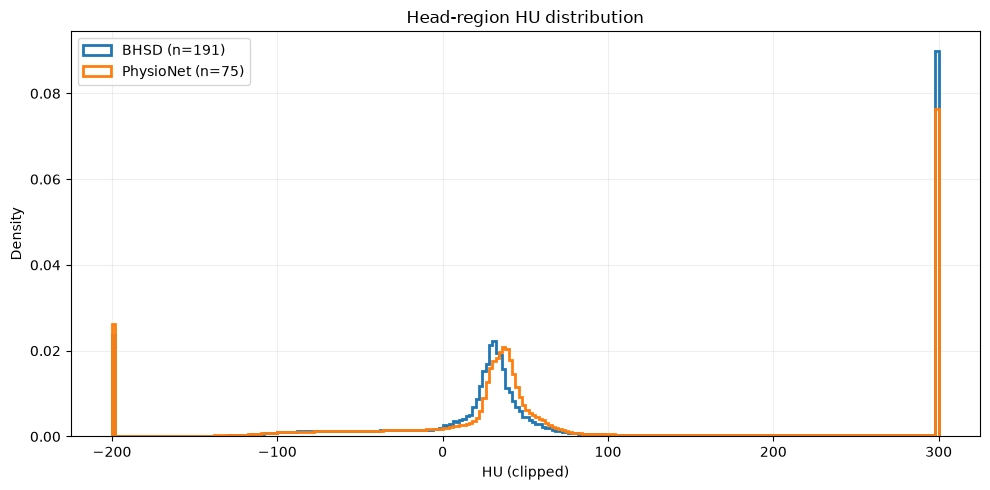

In [7]:
# 5. HU histogram 비교 — 동일 범위, case당 동일 최대 표본 수
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.linspace(HU_RANGE[0], HU_RANGE[1], 251)
for source, color in [('BHSD', 'tab:blue'), ('PhysioNet', 'tab:orange')]:
    values = np.concatenate(sampled_hu[source])
    ax.hist(values, bins=bins, density=True, histtype='step', linewidth=2, label=f'{source} (n={len(sampled_hu[source])})', color=color)
ax.set(title='Head-region HU distribution', xlabel='HU (clipped)', ylabel='Density')
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'hu_histogram.png', dpi=160)
plt.show()

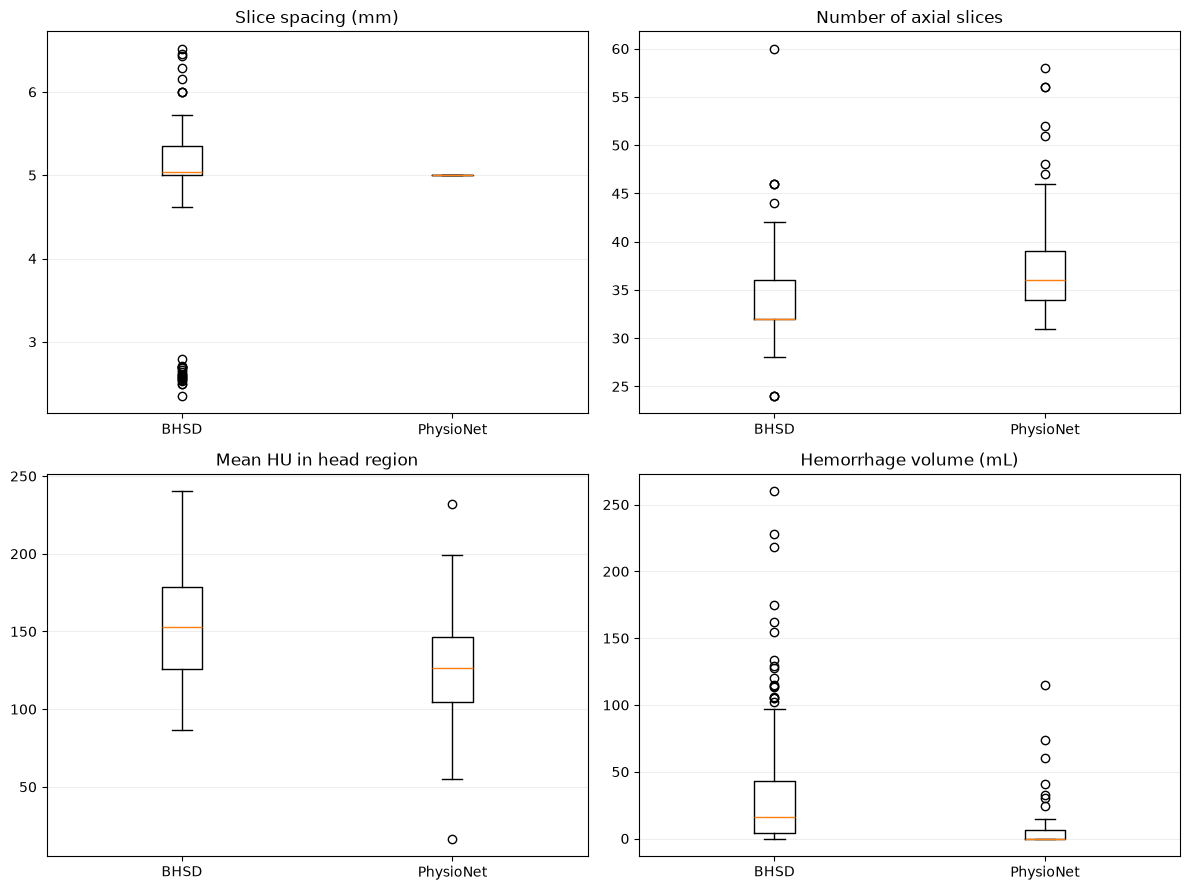

In [11]:
# 6. spacing, slice 수, 출혈 부피 분포

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12, 9),
)

plot_specs = [
    ("spacing_z", "Slice spacing (mm)"),
    ("size_z", "Number of axial slices"),
    ("hu_mean_head", "Mean HU in head region"),
    (
        "hemorrhage_volume_ml",
        "Hemorrhage volume (mL)",
    ),
]

for ax, (column, title) in zip(
    axes.flat,
    plot_specs,
):
    values = [
        case_stats.loc[
            case_stats["source"] == source,
            column,
        ].dropna().to_numpy()
        for source in ["BHSD", "PhysioNet"]
    ]

    ax.boxplot(
        values,
        tick_labels=["BHSD", "PhysioNet"],
        showfliers=True,
    )
    ax.set_title(title)
    ax.grid(
        axis="y",
        alpha=0.2,
    )

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR
    / "geometry_intensity_label_boxplots.png",
    dpi=160,
)

plt.show()

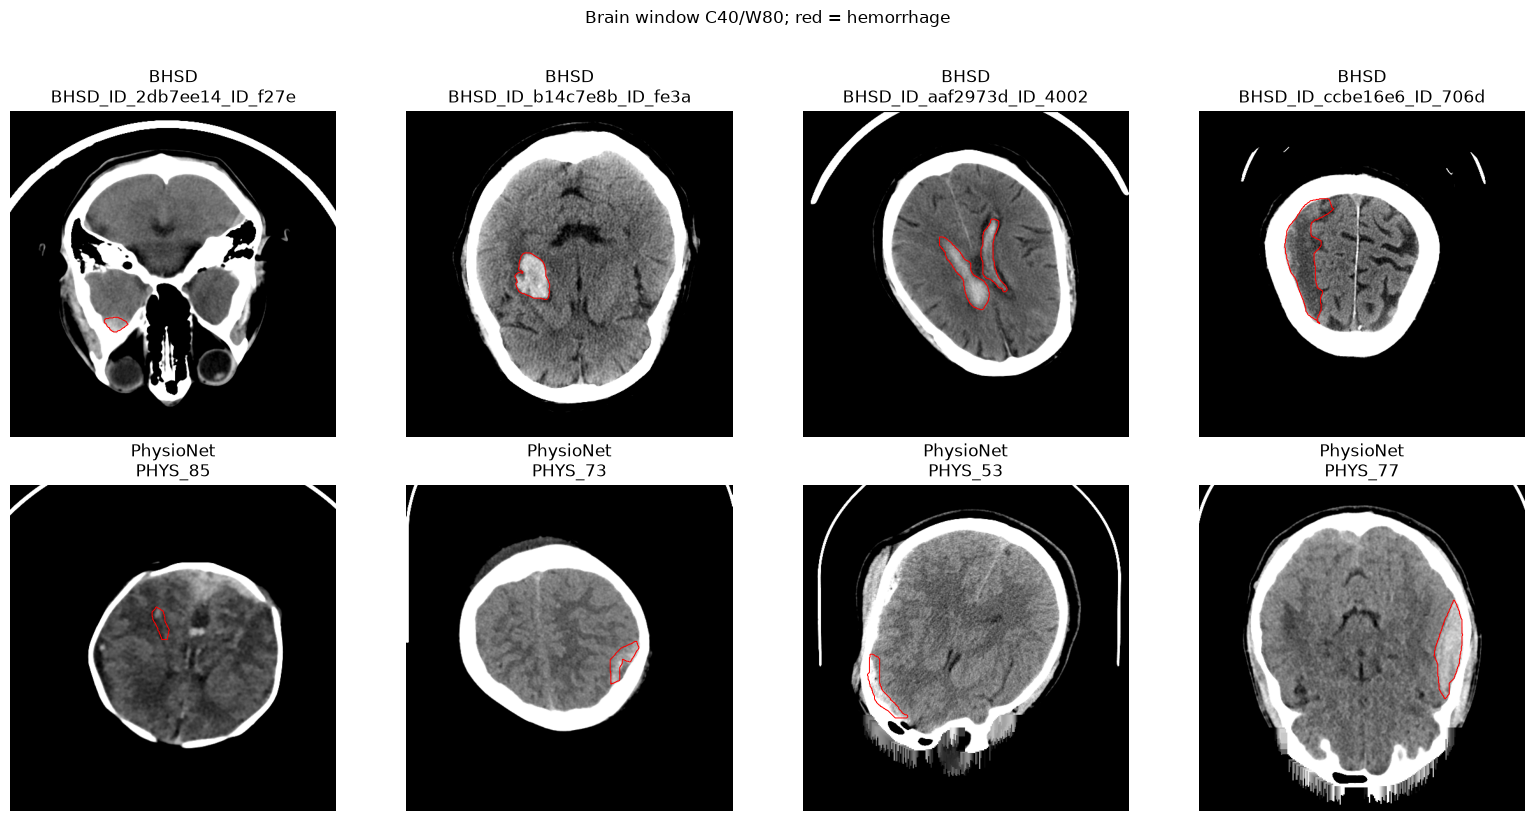

In [12]:
# 7. 동일 window에서 대표 CT 비교
def apply_window(array, center, width):
    low, high = center - width / 2, center + width / 2
    return np.clip((array - low) / (high - low), 0, 1)

def representative_cases(source, count=4):
    subset = case_stats[(case_stats.source == source) & case_stats.has_hemorrhage]
    quantiles = np.linspace(0.15, 0.85, min(count, len(subset)))
    ordered = subset.sort_values('hemorrhage_volume_ml').reset_index(drop=True)
    return [ordered.iloc[int(q * (len(ordered) - 1))].case_id for q in quantiles]

selected = [('BHSD', c) for c in representative_cases('BHSD')] + [('PhysioNet', c) for c in representative_cases('PhysioNet')]
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (source, case_id) in zip(axes.flat, selected):
    item = inventory.loc[inventory.case_id == case_id].iloc[0]
    image = sitk.GetArrayFromImage(sitk.ReadImage(str(item.image_path))).astype(np.float32)
    label = sitk.GetArrayFromImage(sitk.ReadImage(str(item.label_path))) > 0
    if label.any():
        z_counts = label.reshape(label.shape[0], -1).sum(axis=1)
        z = int(z_counts.argmax())
    else:
        z = image.shape[0] // 2
    ax.imshow(apply_window(image[z], center=40, width=80), cmap='gray', vmin=0, vmax=1)
    ax.contour(label[z], levels=[0.5], colors='red', linewidths=0.7)
    ax.set_title(f'{source}\n{case_id[:24]}')
    ax.axis('off')
fig.suptitle('Brain window C40/W80; red = hemorrhage', y=1.02)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'representative_brain_window.png', dpi=160, bbox_inches='tight')
plt.show()

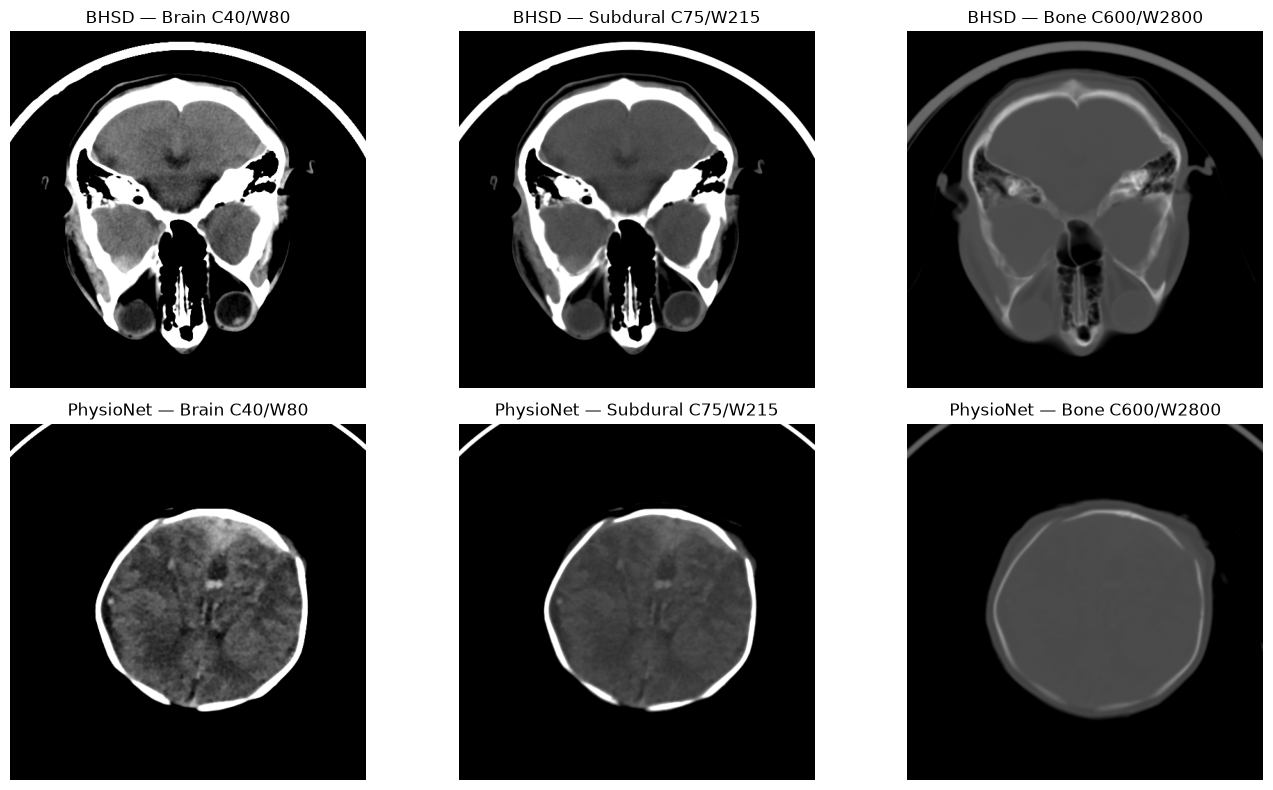

In [13]:
# 8. 같은 case를 brain/subdural/bone window로 확인
windows = [('Brain', 40, 80), ('Subdural', 75, 215), ('Bone', 600, 2800)]
examples = {source: representative_cases(source, count=1)[0] for source in ['BHSD', 'PhysioNet']}
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for row_index, (source, case_id) in enumerate(examples.items()):
    item = inventory.loc[inventory.case_id == case_id].iloc[0]
    image = sitk.GetArrayFromImage(sitk.ReadImage(str(item.image_path))).astype(np.float32)
    label = sitk.GetArrayFromImage(sitk.ReadImage(str(item.label_path))) > 0
    z = int(label.reshape(label.shape[0], -1).sum(axis=1).argmax()) if label.any() else image.shape[0] // 2
    for column_index, (name, center, width) in enumerate(windows):
        ax = axes[row_index, column_index]
        ax.imshow(apply_window(image[z], center, width), cmap='gray', vmin=0, vmax=1)
        ax.set_title(f'{source} — {name} C{center}/W{width}')
        ax.axis('off')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'multi_window_examples.png', dpi=160)
plt.show()

In [14]:
# 9. 간단한 표준화 차이 지표와 분석 manifest 저장
features = ['spacing_z', 'size_z', 'hu_mean_head', 'hu_std_head', 'hu_p50_head', 'hemorrhage_volume_ml']
effect_rows = []
for feature in features:
    a = case_stats.loc[case_stats.source == 'BHSD', feature].dropna().to_numpy(float)
    b = case_stats.loc[case_stats.source == 'PhysioNet', feature].dropna().to_numpy(float)
    pooled = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1)) / (len(a)+len(b)-2))
    effect = (a.mean() - b.mean()) / pooled if pooled > 0 else np.nan
    effect_rows.append({'feature': feature, 'BHSD_mean': a.mean(), 'PhysioNet_mean': b.mean(), 'standardized_difference': effect})
effects = pd.DataFrame(effect_rows)
effects.to_csv(OUTPUT_DIR / 'standardized_differences.csv', index=False)
display(effects.sort_values('standardized_difference', key=lambda s: s.abs(), ascending=False))
manifest = {
    'dataset_root': str(DATASET_ROOT),
    'seed': SEED,
    'max_voxels_per_case': MAX_VOXELS_PER_CASE,
    'hu_range': list(HU_RANGE),
    'case_counts': inventory.groupby('source').size().to_dict(),
    'outputs': sorted(path.name for path in OUTPUT_DIR.iterdir()),
}
(OUTPUT_DIR / 'analysis_manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print('분석 결과:', OUTPUT_DIR)

,feature,BHSD_mean,PhysioNet_mean,standardized_difference
4,hu_p50_head,32.376963,36.840000,-1.341749
1,size_z,33.277487,37.520000,-0.877784
3,hu_std_head,372.176922,323.011641,0.804820
2,hu_mean_head,153.978969,126.125707,0.791051
5,hemorrhage_volume_ml,33.311926,7.248535,0.679238
0,spacing_z,4.935357,5.000000,-0.089815


분석 결과: /home/stu03/workspace/model/runs/analysis/bhsd_physionet_domain_comparison


## 병변 크기와 Dice 관계 분석
H-N00 validation에서 출혈 부피가 Dice 차이를 설명하는지 확인합니다.


In [15]:
# 10. H-N00 case별 Dice와 출혈 부피 결합
BASELINE_SUMMARY = ROOT / "runs/nnunet/Dataset001_ICHBinary/nnUNetTrainerICHBaseline__ICHPlansBaselineV1__3d_fullres/fold_0/validation/summary.json"
baseline_summary = json.loads(BASELINE_SUMMARY.read_text(encoding="utf-8"))
dice_rows = []
for item in baseline_summary["metric_per_case"]:
    name = item["reference_file"].replace("\\", "/").rsplit("/", 1)[-1]
    metric = item["metrics"]["1"]
    dice_rows.append({"case_id": name.removesuffix(".nii.gz"), "dice": float(metric["Dice"]), "n_ref": int(metric["n_ref"])})
volume_dice = pd.DataFrame(dice_rows).merge(
    case_stats[["case_id", "source", "hemorrhage_volume_ml"]],
    on="case_id", validate="one_to_one",
)
positive = volume_dice[(volume_dice.n_ref > 0) & (volume_dice.hemorrhage_volume_ml > 0)].copy()
volume_dice.to_csv(OUTPUT_DIR / "validation_volume_dice.csv", index=False)
display(volume_dice.groupby("source").agg(
    cases=("case_id", "size"),
    positive_cases=("n_ref", lambda x: int((x > 0).sum())),
    mean_dice=("dice", "mean"),
    median_dice=("dice", "median"),
))


,cases,positive_cases,mean_dice,median_dice
source,,,,
BHSD,28,28,0.624656,0.666136
PhysioNet,12,7,0.276638,0.000000


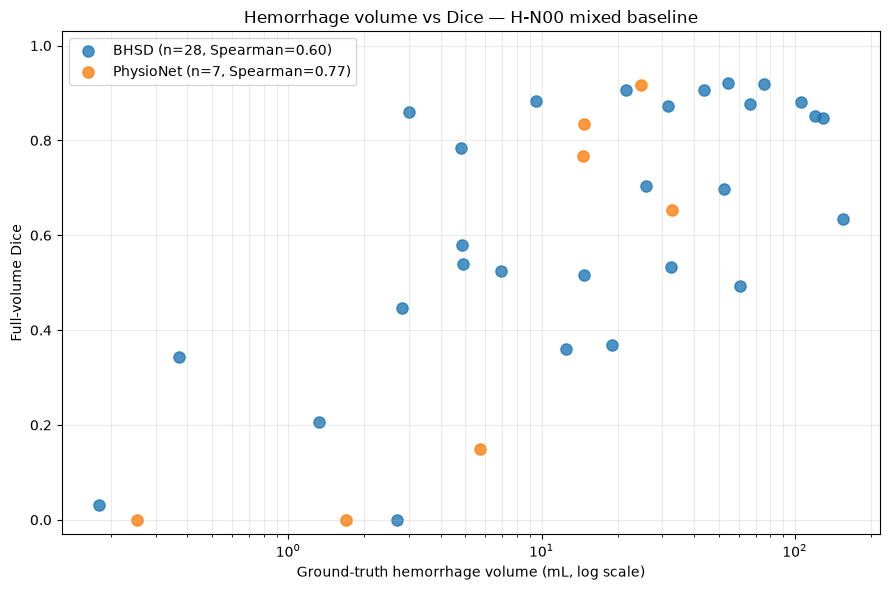

In [16]:
# 11. 출혈 부피 vs Dice
colors = {"BHSD": "tab:blue", "PhysioNet": "tab:orange"}
fig, ax = plt.subplots(figsize=(9, 6))
for source in ["BHSD", "PhysioNet"]:
    subset = positive[positive.source == source]
    rho = np.corrcoef(subset.hemorrhage_volume_ml.rank(), subset.dice.rank())[0, 1]
    ax.scatter(
        subset.hemorrhage_volume_ml, subset.dice,
        s=65, alpha=0.8, color=colors[source],
        label=f"{source} (n={len(subset)}, Spearman={rho:.2f})",
    )
ax.set_xscale("log")
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel("Ground-truth hemorrhage volume (mL, log scale)")
ax.set_ylabel("Full-volume Dice")
ax.set_title("Hemorrhage volume vs Dice — H-N00 mixed baseline")
ax.grid(alpha=0.25, which="both")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "hemorrhage_volume_vs_dice.png", dpi=160)
plt.show()


,source,volume_group,cases,mean_dice,median_dice,std_dice
0,BHSD,<1 mL,2,0.188090,0.188090,0.220861
1,BHSD,1–5 mL,7,0.487943,0.539745,0.304412
2,BHSD,5–20 mL,5,0.530359,0.516025,0.211871
3,BHSD,≥20 mL,14,0.789057,0.862615,0.148165
4,PhysioNet,<1 mL,1,0.000000,0.000000,NaN
5,PhysioNet,1–5 mL,1,0.000000,0.000000,NaN
6,PhysioNet,5–20 mL,3,0.583290,0.766806,0.377238
7,PhysioNet,≥20 mL,2,0.784890,0.784890,0.186955


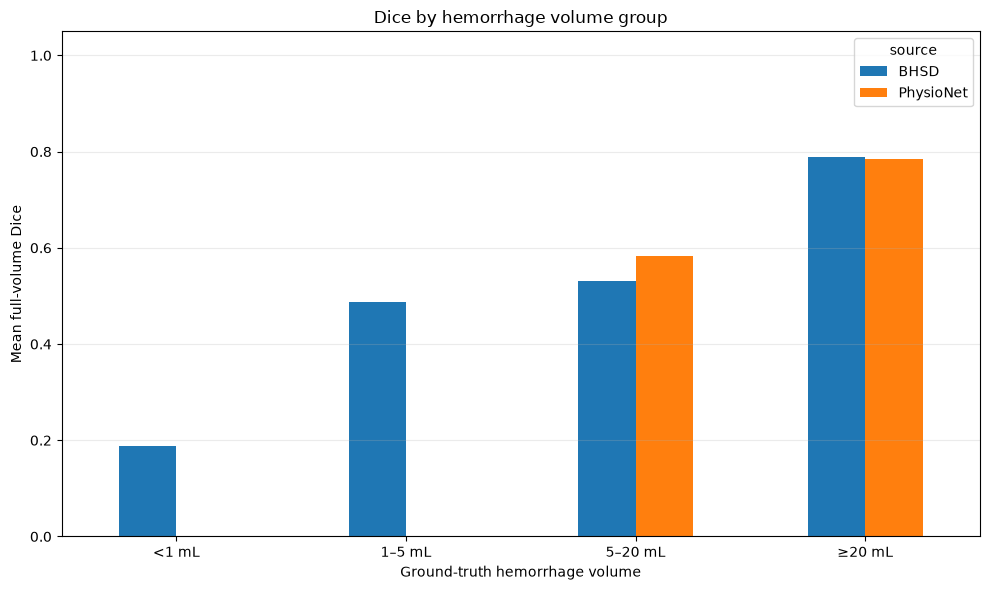

In [17]:
# 12. 출혈 부피 구간별 Dice 비교
volume_labels = ["<1 mL", "1–5 mL", "5–20 mL", "≥20 mL"]
positive["volume_group"] = pd.cut(
    positive.hemorrhage_volume_ml,
    bins=[0, 1, 5, 20, np.inf],
    labels=volume_labels,
    right=False,
)
group_summary = (
    positive.groupby(["source", "volume_group"], observed=False)
    .agg(cases=("case_id", "size"), mean_dice=("dice", "mean"), median_dice=("dice", "median"), std_dice=("dice", "std"))
    .reset_index()
)
group_summary.to_csv(OUTPUT_DIR / "dice_by_hemorrhage_volume_group.csv", index=False)
display(group_summary)
pivot = group_summary.pivot(index="volume_group", columns="source", values="mean_dice").reindex(volume_labels)
ax = pivot.plot.bar(
    figsize=(10, 6),
    color=[colors.get(column) for column in pivot.columns],
    ylim=(0, 1.05), rot=0,
)
ax.set_xlabel("Ground-truth hemorrhage volume")
ax.set_ylabel("Mean full-volume Dice")
ax.set_title("Dice by hemorrhage volume group")
ax.grid(axis="y", alpha=0.25)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "dice_by_hemorrhage_volume_group.png", dpi=160)
plt.show()
